# Proyecto — «Puente»: ML causal en producción local

**Semana 4 · construcción guiada en clase + tarea individual sobre `real/ihdp`.**

En este proyecto construyes, pieza por pieza, un servicio causal local completo: un estimador con incertidumbre, una tarjeta de modelo, un registro de versiones con hash y alias `champion`, un servicio FastAPI que se abstiene fuera del soporte, y una puerta causal `pasa / alerta / falla` sobre ventanas de producción. Es el esqueleto del proyecto final del curso, en miniatura.

## El mapa

| Concepto del libro | Cap. | Se materializa en |
|---|---|---|
| El estimando se declara antes de mirar | 1 | `pregunta_jobs.md` (léela primero) |
| Cinco acciones; abstención de primera clase | 2 | `monitor.py`, `servicio_core.py` |
| Contrato C-01 (roles) | 3 | `datos.py` |
| Contrato C-09 (hashes, versión, champion) | 4 | `registro.py` |
| Contrato C-10 (splits sembrados, la pared) | 5 | `datos.py` |
| Validez temporal: la trampa | 6 | `score_post` en `estimacion.py` |
| C-02: SMD / PSI / ESS con umbrales calibrados | 7 | `estimacion.py`, `monitor.py` |
| Benchmark como producto (C-11) | 8 | todo corre sobre un escenario declarado |
| (puente) Lo que DML le exige al dato | 9 | `aipw_crossfit` en `estimacion.py` |

## Cómo se trabaja

1. **El código se escribe en los archivos `.py`**, no en el notebook: cada uno trae TODOs numerados con pistas (TODO-1 … TODO-22). Este notebook es el conductor: explica, ejecuta los checkpoints y deja constancia de tus resultados.
2. Cada bloque de la clase termina con un `make <objetivo>` que debe salir en verde con los números esperados.
3. La **tarea** (sección 7) reemplaza el escenario `real/jobs` por `real/ihdp` y es lo que se entrega (ver `ENTREGA.md`).


## 0. Preparación

Entorno del curso activado (`python -m pip install -r requirements.txt` si falta algo).
El estado de arranque correcto: `make verificar` **falla** con `TODO-1` — así se empieza.

> Si tu máquina no tiene `make`, los objetivos son atajos de un comando: `make verificar` = `python3 datos.py`, `make estimar` = `python3 estimacion.py`, `make registrar` = `python3 registro.py`, `make ventanas` = `python3 monitor.py`, `make humo` = `python3 humo.py`.

In [1]:
# Entorno: debe imprimir las versiones y los archivos del proyecto
import pathlib, sys
print("python:", sys.version.split()[0])
try:
    import numpy, scipy
    print("numpy", numpy.__version__, "| scipy", scipy.__version__)
except ImportError as e:
    print("FALTA:", e, "-> pip install -r requirements.txt")

esperados = ["pregunta_jobs.md", "datos.py", "estimacion.py", "registro.py",
             "monitor.py", "servicio_core.py", "servicio.py", "humo.py", "Makefile"]
presentes = [f.name for f in pathlib.Path(".").glob("*")]
print("archivos:", ", ".join(f for f in esperados if f in presentes))
assert len([f for f in esperados if f in presentes]) == len(esperados)


python: 3.13.18
numpy 2.3.5 | scipy 1.17.0
archivos: pregunta_jobs.md, datos.py, estimacion.py, registro.py, monitor.py, servicio_core.py, servicio.py, humo.py, Makefile


In [2]:
# Checkpoint de arranque: en el kit limpio falla con TODO-1; aquí ya pasa.
# El fallo original quedó registrado en BITACORA.md §1 y en el tag semana4-kit-original.
!make verificar


python3 datos.py


Esquema C-01: EsquemaCausal(tratamiento='treatment', resultado='re78', covariables=('age', 'educ', 'black', 'hispan', 'married', 'nodegree', 're74', 're75'))
esquema valida contra observed_train: OK (n = 1033, tratados = 262)
Verificación de splits (C-10):
  train        hash OK  (1033 filas, semilla 20240701)
  validation   hash OK  (344 filas, semilla 20240701)
  test         hash OK  (345 filas, semilla 20240701)
La pared (C-10):
  pared OK: truth_train.csv no existe en el paquete (reservado)


Si la celda anterior no falló con `TODO-1`, algo viene ya resuelto: pide una copia limpia de este proyecto.

## 1. La pregunta antes que el código (Cap. 1)

Abre [`pregunta_jobs.md`](pregunta_jobs.md) y léela completa: pregunta causal, estimando, población, supuestos con su clase (`observable` / `no_observable`), y qué NO afirma el prototipo.

> **Para tu entrega:** en la sección 7 escribirás tu propia pregunta para `real/ihdp`, con el mismo formato. Ve anotando qué estimando te interesa y qué supuestos declararás.

## 2. El contrato de roles y la pared (Caps. 3 y 5)

Completas **TODO-1, TODO-2 y TODO-3** en `datos.py`:

- `TODO-1` — `EsquemaCausal.validar`: tres rechazos que *nombran al culpable* (columna ausente, doble rol, tratamiento constante).
- `TODO-2` — `verificar_splits`: recomputar el SHA-256 de las tres particiones contra lo que declaró el productor en `splits.json`.
- `TODO-3` — `comprobar_pared`: la verdad del escenario (`truth_*.csv`) no existe en el paquete; ese `FileNotFoundError` **es** la pared.
> **Entrega:** en esta versión los 22 TODOs ya están resueltos y los cinco
> checkpoints ejecutan en verde; el fallo inicial con `TODO-1` quedó registrado en
> `BITACORA.md` §1 y en el tag `semana4-kit-original`.


In [3]:
# Checkpoint 1: los tres hash OK y la pared
!make verificar


python3 datos.py


Esquema C-01: EsquemaCausal(tratamiento='treatment', resultado='re78', covariables=('age', 'educ', 'black', 'hispan', 'married', 'nodegree', 're74', 're75'))
esquema valida contra observed_train: OK (n = 1033, tratados = 262)
Verificación de splits (C-10):
  train        hash OK  (1033 filas, semilla 20240701)
  validation   hash OK  (344 filas, semilla 20240701)
  test         hash OK  (345 filas, semilla 20240701)
La pared (C-10):
  pared OK: truth_train.csv no existe en el paquete (reservado)


**Salida esperada** (escenario `real/jobs`):

```text
esquema valida contra observed_train: OK (n = 1033, tratados = 262)
  train        hash OK  (1033 filas, semilla 20240701)
  validation   hash OK  (344 filas, semilla 20240701)
  test         hash OK  (345 filas, semilla 20240701)
  pared OK: truth_train.csv no existe en el paquete (reservado)
```

In [4]:
# Provoca el fallo a propósito: el origen renombró una columna
import sys; sys.path.insert(0, ".")
from datos import EsquemaCausal
esquema = EsquemaCausal()
try:
    esquema.validar(["treatment", "re78", "age", "black"], [0, 1, 0, 1])  # sin 'educ'
except ValueError as e:
    print("rechazado como corresponde:", e)


rechazado como corresponde: columna(s) del esquema ausentes en los datos: ['educ', 'hispan', 'married', 'nodegree', 're74', 're75']


## 3. El efecto con incertidumbre (Caps. 1, 6, 7 — y el puente al 9)

Completas **TODO-4 … TODO-8, TODO-21 y TODO-22** en `estimacion.py`:

- `TODO-4` — `ate_ols`: la referencia ingenua (OLS con controles + IC).
- `TODO-21` — **`aipw_crossfit` — la pieza del día**: el ATE doblemente robusto con cross-fitting K=5 — outcome por brazo y propensity ajustados *fuera* del fold que predicen, y el score AIPW por unidad (la influence function).
- `TODO-22` — `estratos_nodegree`: la media de scores por estrato con su IC, con el corte **pre-declarado** en la tarjeta.
- `TODO-8` — la trampa: una columna calculada con el resultado («score de éxito del programa»).

In [5]:
# Checkpoint 2: el efecto, el AIPW y los estratos
!make estimar


python3 estimacion.py


diferencia cruda E[Y|D=1]-E[Y|D=0] = 1600.8 USD
ATE OLS (8 controles) = 1596.0 | SE = 301.6 | IC95 = [1004.8, 2187.3]
AIPW cross-fitting K=5 = 1638.6 | SE = 325.0 | IC95 = [1001.6, 2275.7]
trampa score_post      = 172.4  <- el coeficiente se vació
estrato nodegree=1 (sin título, n=568): efecto 1060.1 IC95 [233.1, 1887.2]
estrato nodegree=0 (con título, n=465): efecto 2345.2 IC95 [1356.9, 3333.4]
ESS = 729 (ESS/n = 0.71) | rango e = [0.092, 0.530] | solapamiento = 100%
SMD máx = 0.19
artefacto: artifacts/estimacion.json


**Salida esperada** (`real/jobs`):

```text
diferencia cruda E[Y|D=1]-E[Y|D=0] = 1600.8 USD
ATE OLS (8 controles) = 1596.0 | SE = 301.6 | IC95 = [1004.8, 2187.3]
AIPW cross-fitting K=5 = 1638.6 | SE = 325.0 | IC95 = [1001.6, 2275.7]
trampa score_post      = 172.4  <- el coeficiente se vació
estrato nodegree=1 (sin título, n=568): efecto 1060.1 IC95 [233.1, 1887.2]
estrato nodegree=0 (con título, n=465): efecto 2345.2 IC95 [1356.9, 3333.4]
ESS = 729 (ESS/n = 0.71) | rango e = [0.092, 0.530] | solapamiento = 100%
SMD máx = 0.19
```

**Cómo se lee:**

- **OLS y AIPW — dos estimadores distintos, misma conclusión** (1 596 vs 1 638): eso compra la doble robustez. Y ningún nuisance vio a la unidad que predice: la exigencia número uno del Cap. 9, en 15 líneas.
- **Los estratos sugieren** que el programa rinde más en quienes tienen título (2 345 vs 1 060), pero los intervalos **se solapan**: heterogeneidad sugerida, no concluyente. El servicio lo dirá con esa letra.
- **La trampa** vacía el coeficiente (172) sin lanzar ningún error: la fuga no penaliza el ajuste predictivo: al contrario, lo mejora. Por eso ninguna métrica de ajuste la detecta.

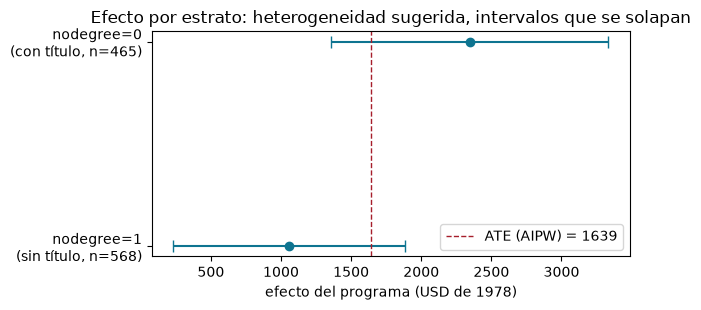

In [6]:
%matplotlib inline
# Los estratos, en un gráfico: intervalos que se solapan
import json
import matplotlib.pyplot as plt

try:
    r = json.load(open("artifacts/estimacion.json"))
except FileNotFoundError:
    print("Corre antes: make estimar (con los TODO del bloque de estimación resueltos)")
    r = None

if r is not None:
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    labels, xs, errs = [], [], []
    for v, h in r["estratos"]["hojas"].items():
        labels.append("nodegree=" + str(v) + "\n(" + h["etiqueta"] + ", n=" + str(h["n"]) + ")")
        xs.append(h["efecto"])
        errs.append(1.96 * h["se"])
    ax.errorbar(xs, range(len(xs)), xerr=errs, fmt="o", capsize=4, color="#0E7490")
    ax.axvline(r["ate_aipw"], color="#A61E2B", ls="--", lw=1,
               label="ATE (AIPW) = {:.0f}".format(r["ate_aipw"]))
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("efecto del programa (USD de 1978)")
    ax.set_title("Efecto por estrato: heterogeneidad sugerida, intervalos que se solapan")
    ax.legend(); fig.tight_layout()
    fig  # última expresión: el notebook renderiza el PNG del gráfico


## 4. Tarjeta, registro y champion (Cap. 4)

Completas **TODO-9 … TODO-13** en `registro.py`: la tarjeta (con umbrales calibrados y supuestos clasificados), la versión inmutable `vNNNN` con manifiesto de hashes, la integridad que recomputa, y la promoción atómica de `champion` (que nunca promueve una puerta `falla`).

In [7]:
# Checkpoint 3: registro + mutación detectada + champion
!make registrar


python3 registro.py


registrada v0001 | integridad: OK
mutación detectada: SÍ (hash distinto del manifiesto -> bloqueado)
champion -> v0001
champion resuelve a: v0001


**Salida esperada:**

```text
registrada v0001 | integridad: OK
mutación detectada: SÍ (hash distinto del manifiesto -> bloqueado)
champion -> v0001
champion resuelve a: v0001
```

La mutación del ejemplo inyecta **un solo byte** en una copia de `estimacion.json`: el hash deja de coincidir con el manifiesto y la promoción queda bloqueada. La afirmación publicada se refiere a un sujeto con hash.

## 5. Ventanas y puerta causal (Caps. 2 y 7)

Completas **TODO-14 … TODO-18** en `monitor.py`: el PSI, las tres ventanas de producción (sana, deriva, positividad) y la puerta que decide `pasa / alerta / falla` contra los umbrales **declarados en la tarjeta**.

In [8]:
# Checkpoint 4: las tres ventanas
!make ventanas


python3 monitor.py


ventanas de producción (contra champion = v0001, umbrales de la tarjeta: {'smd_max': 0.25, 'psi_alerta': 0.25, 'solape_min': 0.5})



[sana        ] estado = pasa   | acción: continuar
              n=700 | PSI máx = 0.005 | SMD máx = 0.21 | ESS/n = 0.69 | solapamiento = 100%
              - todo dentro de umbral

[deriva      ] estado = alerta | acción: alertar (revisar antes de reentrenar)
              n=1033 | PSI máx = 1.347 | SMD máx = 0.19 | ESS/n = 0.71 | solapamiento = 100%
              - deriva: PSI de age = 1.35 (umbral 0.25)

[positividad ] estado = falla  | acción: abstenerse (bloquear la promoción)
              n=270 | PSI máx = 3.237 | SMD máx = 5.24 | ESS/n = 1.0 | solapamiento = 0%
              - solapamiento roto: 0% de unidades con e en [0.05, 0.95] (mínimo 50%)



**Salida esperada:**

```text
[sana        ] estado = pasa   | acción: continuar
[deriva      ] estado = alerta | acción: alertar (revisar antes de reentrenar)
              - deriva: PSI de age = 1.35 (umbral 0.25)
[positividad ] estado = falla  | acción: abstenerse (bloquear la promoción)
              - solapamiento roto: 0% de unidades con e en [0.05, 0.95] (mínimo 50%)
```

**Responde en la celda siguiente** (2–4 líneas por pregunta):

1. En la ventana `positividad`, el ESS/n da 1.0 — ¿por qué esa cifra *no* es una buena señal, y cuál es la señal que sí rompe la puerta?
2. En la ventana `deriva` el SMD queda en 0.19 — ¿por qué la puerta no se alerta por balance, y qué pregunta distinta responde el PSI?
3. Con la señal de `deriva` en la mano: ¿cuál de las cinco acciones corresponde, y qué NO puedes afirmar sobre la causa del cambio?

In [9]:
# Tus respuestas del bloque de ventanas
respuesta_v1 = """
ESS/n ≈ 1 no es una buena señal: dentro de cada brazo los pesos IPW son casi
constantes (el tratamiento se volvió casi determinista dado re74), así que no hay
variación de pesos que el ESS pueda penalizar. La señal que sí rompe la puerta es el
solapamiento: 0 % de unidades con ê en [0,05; 0,95], por debajo del mínimo de 50 %.
Sin solape no hay contrafactual que estimar: la ponderación parece eficiente porque
está ponderando una comparación que no existe.
"""
respuesta_v2 = """
El SMD que evalúa la puerta es el balance INTERNO de la ventana (tratados contra
controles dentro de la ventana). Envejecer a todos por igual desplaza ambos brazos, así
que el contraste no se mueve: 0,19. El PSI responde otra pregunta: si la distribución
de la covariable se parece a la de ENTRENAMIENTO (referencia), no si está balanceada.
Por eso la deriva la detecta el PSI (age = 1,35) y no el SMD.
"""
respuesta_v3 = """
Corresponde "alertar (revisar antes de reentrenar)": es una señal de proceso, no un
fallo del estimando, y no bloquea la promoción. No puedo afirmar que la causa sea el
envejecimiento real de la población, ni que el efecto haya cambiado: el PSI mide un
cambio en la distribución de una covariable, no un mecanismo ni un efecto. Lo único
que sé es que la población de entrada ya no se parece a la de entrenamiento.
"""


## 6. El servicio: abstención y efecto del estrato (Cap. 2 y Parte IV)

Completas **TODO-19 y TODO-20** en `servicio_core.py`: el bundle champion (el servicio **no** lee CSV — el bundle viaja, los datos no) y la consulta con abstención fuera del soporte **y efecto del estrato** dentro.

In [10]:
# Checkpoint 5: el humo del servicio
!make humo


python3 humo.py


/salud: 200 {'estado': 'ok', 'version': 'v0001', 'estimando': 'ATE de treatment sobre re78 (efecto total)'}
/efecto: 200 efecto=1638.6 ic95=[1001.6, 2275.7] version=v0001
/consulta dentro: 200 estado=respuesta efecto=1060.1
/consulta fuera (age=99): 200 estado=abstencion motivo=age=99 fuera de [18.0, 54.0] (sin número)
determinismo: dos llamadas idénticas -> iguales
/efecto_individual dentro: 200 estado=respuesta efecto=398.8 ic95=[-1663.3, 2461.0] r2=0.012
/efecto_individual fuera (age=99): 200 estado=abstencion (sin número)
/efecto?formato=texto: 200 (8 líneas) — lecturas legibles OK
/efecto_individual?formato=texto: 200 encabezado OK
/ (formulario): 200 — 8 campos
/calcular: 200 informe generado

HUMO: OK


**Salida esperada:**

```text
/salud: 200 {'estado': 'ok', 'version': 'v0001', ...}
/efecto: 200 efecto=1638.6 ic95=[1001.6, 2275.7] version=v0001
/consulta dentro: 200 estado=respuesta efecto=1060.1
/consulta fuera (age=99): 200 estado=abstencion motivo=age=99 fuera de [18.0, 54.0] (sin número)
determinismo: dos llamadas idénticas -> iguales
HUMO: OK
```

Fíjate: la abstención devuelve HTTP **200** — es una respuesta de primera clase, no un error. Y `/efecto` y `/consulta` responden **estimandos distintos** (el poblacional contra el del estrato), cada uno declarando qué cubre su intervalo.

Para levantar el servicio de verdad (opcional, en una terminal):

```bash
make servir        # y en otra terminal:
curl -s localhost:8000/efecto | python -m json.tool
curl -s -X POST localhost:8000/consulta -H "Content-Type: application/json" -d '{"age": 99, "educ": 10, "black": 1, "hispan": 0, "married": 0, "nodegree": 1, "re74": 2000, "re75": 1500}' | python -m json.tool
```

## 7. TAREA — El mismo puente sobre `real/ihdp` (lo que se entrega)

El escenario `real/ihdp` (Hill 2011, sintético): 747 unidades, **25 covariables**, tratamiento `treatment`, resultado `outcome` (puntaje cognitivo a los 3,5 años), ATE de referencia ~4,0 según la literatura, y **efectos heterogéneos por diseño**. Las particiones son 448 / 149 / 150.

Tu trabajo: **adaptar el prototipo completo al nuevo escenario y reportar tus números.** Nadie te da el esquema: lo construyes desde los metadatos del escenario.

In [11]:
# Explora el escenario: esto es lo único que te dan
import json, pathlib
base = pathlib.Path(".").resolve()
while not (base / "data_benchmark_causal").is_dir():
    base = base.parent
esc = base / "data_benchmark_causal" / "causal_benchmark_synthetic" / "datasets" / "real" / "ihdp"
meta = json.loads((esc / "metadata.json").read_text())
ident = json.loads((esc / "identification.json").read_text())
print("descripción:", meta["description"])
print("tratamiento:", meta["treatment"], "| resultado:", meta["outcome"])
print("covariables:", ident["valid_adjustment_sets"][0])
print("referencia del DGP:", meta["what_is_real"][:70])


descripción: IHDP-style synthetic dataset with heterogeneous treatment effects
tratamiento: Intervention program for low birth weight children | resultado: Cognitive test scores at age 3.5
covariables: ['bw', 'b.head', 'preterm', 'birth.o', 'nnhealth', 'momage', 'sex', 'twin', 'b.marr', 'mom.lths', 'mom.hs', 'mom.scoll', 'cig', 'first', 'booze', 'drugs', 'work.dur', 'prenatal', 'ark', 'ein', 'har', 'mia', 'pen', 'tex', 'was']
referencia del DGP: ATE reference value (~4.0 from literature), number of units/covariates


In [12]:
# Arranque de la tarea: el escenario se cambia con una variable de entorno
import os
os.environ["SIC_ESCENARIO"] = "real/ihdp"
print("ESCENARIO ->", os.environ["SIC_ESCENARIO"])
# Tu adaptación (edítalos en los .py y vuelve a correr los make):
#   datos.py      : EsquemaCausal -> tratamiento 'treatment', resultado 'outcome'
#                  y las 25 covariables que acabas de listar.
#   estimacion.py : estratos_nodegree -> TU corte, pre-declarado con su regla.
#   monitor.py   : ventana_deriva y ventana_positividad -> adáptalas a una
#                  covariable continua de ihdp (p. ej. bw o momage).
# Luego: make verificar && make estimar && make registrar && make ventanas && make humo


ESCENARIO -> real/ihdp


### Tus números (`real/ihdp`)

Resultados de `SIC_ESCENARIO=real/ihdp make demo` (semilla 4242, K=5):

| Pieza | Tu resultado |
|---|---|
| Diferencia cruda (train) | 10,3 puntos |
| ATE OLS + IC95 | 4,8 [3,8; 5,8] (SE 0,5) |
| **ATE AIPW (cross-fitting) + IC95** | **5,2 [3,9; 6,4]** (SE 0,6) |
| ESS / n y rango de $\hat e$ | 388 / 448 = 0,87 · ê ∈ [0,071; 0,887] · solape 100 % |
| Estrato 1 (`bw` > mediana) + IC | 7,2 [5,5; 8,8] (n = 224) |
| Estrato 2 (`bw` ≤ mediana) + IC | 3,2 [1,4; 4,9] (n = 224) |
| ¿Los intervalos de los estratos se solapan? | **No** (7,2 contra 3,2; IC disjuntos) |
| Ventana sana → estado | `pasa` (PSI 0,02 · SMD 0,33 · solape 100 %) |
| Ventana deriva → estado y señal | `alerta` — PSI de `bw` = 0,88 (umbral 0,25) |
| Ventana positividad → estado y señal | `falla` — solape 0 % (mínimo 30 %) |
| Humo: `/efecto` y `/consulta` | `/efecto` 5,2 [3,9; 6,4] · `/consulta` 7,2 · fuera de soporte → abstención 200 sin número |

**Reglas de la tarea (cumplidas, con su registro en `BITACORA.md` §8):**

- El corte es mío y está declarado **antes** de mirar los efectos: `bw` (peso al nacer)
  en la mediana de train. Razón: es el eje clínico del IHDP y la mediana preserva
  tamaño en ambas hojas; no se eligió por ganancia de varianza.
- Umbrales recalibrados: `solape_min` 0,50 → **0,30** (25 covariables estrechan el
  soporte); `smd_max` 0,25 → **0,50** (el máximo de 25 SMD tiene EE ≈ 0,096, así que
  el ruido esperado llega a 0,3–0,4); `psi_alerta` se queda en 0,25. Ver justificación
  completa en `BITACORA.md` §8.3.
- La referencia del DGP (~4,0) **no** se usó para estimar ni decidir: solo se compara
  al final, y el IC del AIPW la contiene.

La pregunta, el estimando y los supuestos con su clase están en [`pregunta_ihdp.md`](pregunta_ihdp.md).

### Humo sobre `real/ihdp` (salida pegada)

```text
$ SIC_ESCENARIO=real/ihdp make humo
/salud: 200 {'estado': 'ok', 'version': 'v0001', 'estimando': 'ATE de treatment sobre outcome (efecto total)'}
/efecto: 200 efecto=5.2 ic95=[3.9, 6.4] version=v0001
/consulta dentro: 200 estado=respuesta efecto=7.2
/consulta fuera (bw=4.05316): 200 estado=abstencion motivo=bw=4.05316 fuera de [-3.1332, 3.0532] (sin número)
determinismo: dos llamadas idénticas -> iguales

HUMO: OK
```

> Los checkpoints de este notebook corren sobre `real/jobs` (escenario por defecto); esta
> salida es la del mismo servicio con `SIC_ESCENARIO=real/ihdp` y los artefactos `v0001`
> de ihdp que se entregan.

## 8. Preguntas de cierre (vinculadas a la rúbrica del proyecto final)

1. **Estimando:** ¿qué cubre el intervalo de tu AIPW en ihdp — y qué NO cubre? ¿Qué responderías si te preguntan «¿cuánto mejora este niño en particular?»?
2. **Dos piernas:** tu outcome nuisance sigue siendo lineal. ¿Qué le pasaría a esa pierna con 25 covariables y formas no lineales, y por qué el plug-in te preocupa más que el AIPW?
3. **El corte:** ¿por qué la regla del corte va en la tarjeta y no en el código? Da un ejemplo de corte que ganarías por varianza pero no deberías declarar (en `real/jobs`: `black`).
4. **La puerta:** con tu ventana de deriva de ihdp activada, ¿qué acción de las cinco corresponde, y qué le dirías al equipo de producto que pregunta «¿reentrenamos ya?»?
5. **La pared:** nombra dos decisiones que pudiste tomar *solo porque* la verdad no estaba en el paquete.


In [13]:
# Tus respuestas de cierre (2–4 líneas cada una)
cierre_1 = """
El IC [3,9; 6,4] cubre el ATE de la población de entrenamiento (448 niños del IHDP)
bajo no confusión y solape: es un promedio, no un efecto individual. A «¿cuánto mejora
este niño en particular?» la respuesta correcta es que este prototipo no lo estima;
a lo sumo, si el perfil trae bw, informa la media del estrato declarado con su IC y
avisa de que los estratos difieren (7,2 contra 3,2).
"""
cierre_2 = """
Con 25 covariables y formas no lineales, la pierna del outcome (OLS) queda mal
especificada: un sesgo de aproximación que no desaparece al crecer n. El plug-in
(media de μ1−μ0) hereda ese sesgo directamente; el AIPW no, porque el término de
augmentación con los residuales lo corrige si la otra pierna está bien, y su IC ya
incorpora el error de estimar los nuisances. Aun así, la doble robustez descansa en
una logística también lineal: de ahí que el proyecto final pida learners no lineales
y repeated cross-fitting.
"""
cierre_3 = """
Porque la tarjeta es el contrato público: si la regla vive solo en el código, cualquiera
la cambia después de ver los efectos y nadie lo nota; en la tarjeta, cambiarla exige una
versión nueva con hash y queda auditada. Ejemplo de jobs: cortar por black daría hojas
más extremas (y quizá IC más estrechos), pero ganaría por varianza, no por una razón
pre-declarada de interpretabilidad o política; elegirlo después de ver los números es
selección sobre el resultado.
"""
cierre_4 = """
`alerta → alertar (revisar antes de reentrenar)`. Al equipo de producto: todavía no.
La señal (PSI de bw = 0,88) dice que la distribución de entrada cambió, no que el modelo
esté equivocado ni que el efecto haya cambiado. Primero hay que comprobar si la ventana
es real (¿cambió la fuente, la codificación, la población?) y solo entonces reentrenar
con datos que representen la población nueva, registrando una versión nueva.
"""
cierre_5 = """
1) Elegir el corte de heterogeneidad por interpretabilidad (bw en la mediana) sin poder
compararlo con el efecto verdadero por subgrupo: la regla tuvo que declararse antes y
quedó fijada en la tarjeta. 2) Calibrar la puerta solo con señales observables (solape,
PSI, SMD) sin usar el ATE ni τ_i para decidir qué ventana «debería» fallar; si la verdad
hubiera estado en el paquete, la calibración se habría vuelto una profecía.
"""
print("respuestas listas para la entrega")


respuestas listas para la entrega


## Qué entregar

Todo el detalle está en [`ENTREGA.md`](ENTREGA.md). En síntesis: este notebook con salidas y respuestas, tu `artifacts/` de ihdp (con `manifest.json` y `champion`), la tabla de números completa y las adaptaciones declaradas.